In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"  # Es. sahiljit
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)
    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt
    
    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

 [OK] Ambiente rilevato: Locale
 [OK] Directory di lavoro impostata a: /home/matteo/Documents/GitHub/Weather_forecasting


In [ ]:
import numpy as np
import pandas as pd
import src.utils.metrics as metrics
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.svm import SVR, LinearSVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.data.preprocessing import get_joint_data
from sklearn.compose import TransformedTargetRegressor
from sklearn.multioutput import MultiOutputRegressor

def make_svr(kernel, params):
    if kernel == "linear":
        svr = LinearSVR(max_iter=20000, random_state=0, **params)
    else:
        svr = SVR(kernel=kernel, max_iter=200_000, **params)
    return TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), MultiOutputRegressor(svr, n_jobs=-1)),
        transformer=StandardScaler(),
    )

def predict_svr(model, X, y_like):
    pred = pd.DataFrame(model.predict(X), index=y_like.index, columns=y_like.columns)
    pred["tp_mm"] = pred["tp_mm"].clip(lower=0)  # rain >= 0
    return pred

# Optuna
Until now, our hyperparameters were fixed: yes, we did a small grid search, but we thought it was not enough. 

So here we are with Optuna! Here is the definition:

_Optuna is an automatic hyperparameter optimization software framework, particularly designed for machine learning. It features an imperative, define-by-run style user API. Thanks to our define-by-run API, the code written with Optuna enjoys high modularity, and the user of Optuna can dynamically construct the search spaces for the hyperparameters._

We sure love having everything ready to start doing some learning. We will skip redoing everything from scratch, let us start from the "joint" model.

Firstly, we'll need to import it (**perforza** we might add).

In [3]:
import optuna 

/home/matteo/Documents/GitHub/Weather_forecasting/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


After importing it, we need to define a few things.

Let's start from the objective. Obtuna needs to find the best:
1. Kernel
2. Regularization Parameter (C)
3. Epsilon
4. Gamma (if non-linear)
5. n of lag-days

In [ ]:
def objective(trial):
    t2m_lags = trial.suggest_int("t2m_lags", 0, 14) # temperature
    tp_lags  = trial.suggest_int("tp_lags", 0, 7)   # precipitations

    kernel = trial.suggest_categorical("kernel", ["linear", "rbf", "poly"])
    if kernel == "linear":
        C = trial.suggest_float("C", 1e-3, 1, log=True)    # above 1: no gain, and liblinear stops converging
    else:
        C = trial.suggest_float("C", 1e-2, 1e2, log=True)
    params = {
        "C":       C,
        "epsilon": trial.suggest_float("epsilon", 1e-3, 0.3, log=True),  # in standard deviations of the target
    }
    # gamma and degree only exist when the kernel uses them
    if kernel in ("rbf", "poly"):
        params["gamma"] = trial.suggest_float("gamma", 1e-4, 1, log=True)
    if kernel == "poly":
        params["degree"] = trial.suggest_int("degree", 2, 3)
        params["coef0"] = 1

    # Train on train, score on validation. The test set is never used here.
    (X_train, y_train), (X_val, y_val), _ = get_joint_data(t2m_lags, tp_lags)
    model = make_svr(kernel, params).fit(X_train, y_train)
    pred = predict_svr(model, X_val, y_val)

    # MAE of each of the 60 columns divided by that column's std: unit-free, so °C and mm can be averaged
    mae = (y_val - pred).abs().mean()
    score = (mae / y_train.std()).mean()

    # MAE in real units, saved for inspection (they appear in study.trials_dataframe())
    trial.set_user_attr("val_mae_t2m", float(mae["t2m_mean"].mean()))
    trial.set_user_attr("val_mae_tp", float(mae["tp_mm"].mean()))
    return score


Then, we study it

In [5]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)


study = optuna.create_study(
    study_name="joint_svr",
    storage="sqlite:///optuna_joint_svr.db",  # saved to disk: rerunning continues instead of starting over
    load_if_exists=True,
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=0),
)

if len(study.trials) == 0:
    study.enqueue_trial({"t2m_lags": 2, "tp_lags": 2, "kernel": "linear", "C": 1, "epsilon": 0.1})
    study.enqueue_trial({"t2m_lags": 2, "tp_lags": 2, "kernel": "rbf", "C": 1, "epsilon": 0.1, "gamma": 0.04})

study.optimize(objective, n_trials=50, timeout=60 * 60)

print("Best score:", study.best_value)
print("Best params:", study.best_params)
display(study.trials_dataframe().sort_values("value").head(10))

[I 2026-11-23 20:32:27,260] A new study created in RDB with name: joint_svr
[I 2026-11-23 20:33:09,291] Trial 0 finished with value: 0.3492068191580213 and parameters: {'t2m_lags': 2, 'tp_lags': 2, 'kernel': 'linear', 'C': 1, 'epsilon': 0.1}. Best is trial 0 with value: 0.3492068191580213.
[I 2026-11-23 20:33:41,148] Trial 1 finished with value: 0.36473194601509407 and parameters: {'t2m_lags': 2, 'tp_lags': 2, 'kernel': 'rbf', 'C': 1, 'epsilon': 0.1, 'gamma': 0.04}. Best is trial 0 with value: 0.3492068191580213.
[I 2026-11-23 20:33:46,617] Trial 2 finished with value: 0.34316470672955024 and parameters: {'t2m_lags': 8, 'tp_lags': 5, 'kernel': 'linear', 'C': 0.08663279761354557, 'epsilon': 0.012132675491046142}. Best is trial 2 with value: 0.34316470672955024.
[I 2026-11-23 20:34:24,831] Trial 3 finished with value: 0.3705647972564348 and parameters: {'t2m_lags': 13, 'tp_lags': 7, 'kernel': 'rbf', 'C': 1.871450068624068, 'epsilon': 0.1962524585239014, 'gamma': 0.00019237305096546508}. 

KeyboardInterrupt: 

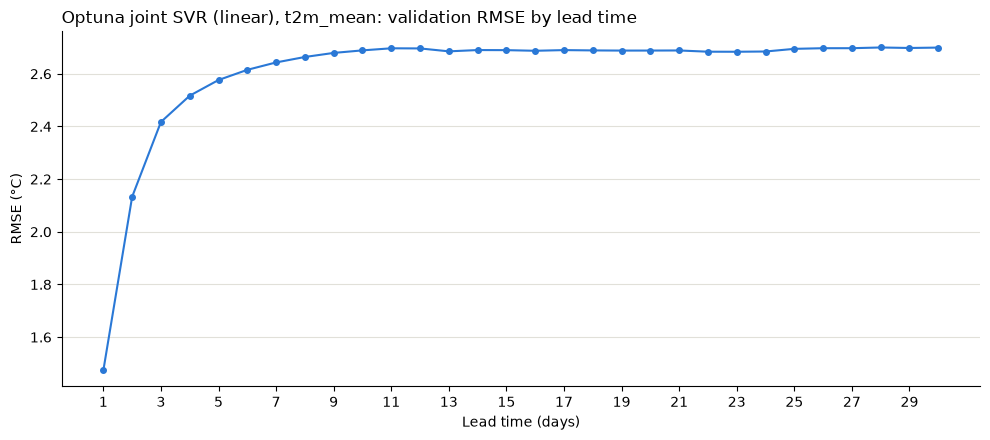

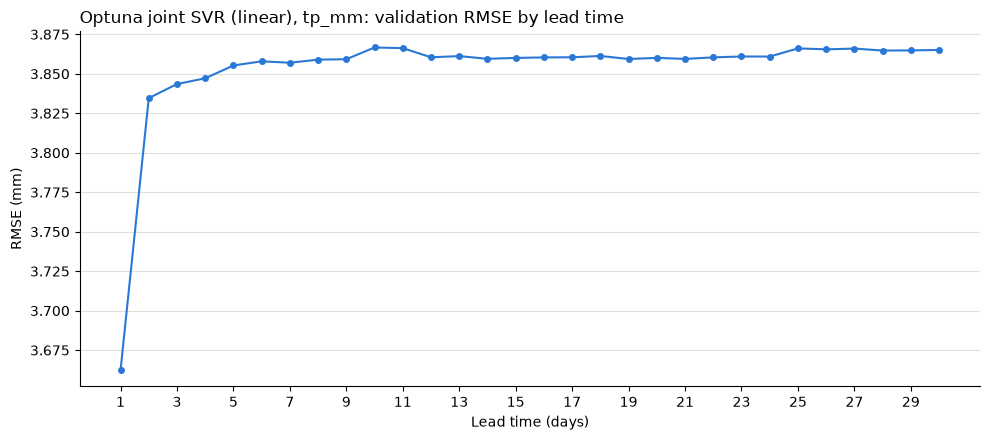

In [ ]:
best = dict(study.best_params)
t2m_lags, tp_lags, kernel = best.pop("t2m_lags"), best.pop("tp_lags"), best.pop("kernel")
if kernel == "poly":
    best["coef0"] = 1

(X_train, y_train), (X_val, y_val), (X_test, y_test) = get_joint_data(t2m_lags, tp_lags)
joint = make_svr(kernel, best).fit(X_train, y_train)

y_train_pred = predict_svr(joint, X_train, y_train)
y_val_pred   = predict_svr(joint, X_val, y_val)
y_test_pred  = predict_svr(joint, X_test, y_test)

for target, unit, tol in [("t2m_mean", "°C", 2), ("tp_mm", "mm", None)]:
    metrics.plot_rmse(y_val[target], y_val_pred[target],
                      f"Optuna joint SVR ({kernel}), {target}: validation RMSE by lead time", unit)
    table = metrics.metrics_table(
        {"Train": (y_train[target], y_train_pred[target]),
         "Val":   (y_val[target],   y_val_pred[target]),
         "Test":  (y_test[target],  y_test_pred[target])},
        tolerance=tol,
    )
    display(table.style.format("{:.3f}"))

**Temperature**: Optuna confirmed what the grid search found. A linear model with a small epsilon is the best SVR, and the number of lag days barely matters. Tuning gave no measurable improvement, so the limit is in the features, not the hyperparameters.

**Rain**: neither SVR beats a constant forecast. Rain needs a different approach.